In [ ]:
%pip install pdfplumber
%pip install contextily
%pip install geopy geopandas

In [ ]:
import requests
import pandas as pd
import pdfplumber
from io import BytesIO
import matplotlib.pyplot as plt
from geopy.geocoders import Nominatim
from geopy.extra.rate_limiter import RateLimiter
import geopandas as gpd
import contextily as ctx

In [15]:
reestr_orig = pd.read_excel(r'C:\Users\User\Downloads\Telegram Desktop\Реестр.xlsx')

c:\Users\User\AppData\Local\Programs\Python\Python312\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


In [ ]:
reestr = reestr_orig.copy()
reestr.columns = reestr.iloc[1]
reestr = reestr[2:]
reestr = reestr.set_index(reestr.columns[0], drop=False)
reestr = reestr[reestr['Категория'].isin(['Малое предприятие', 'Среднее предприятие']) & (reestr['Тип субъекта'] == 'Юридическое лицо') & (reestr['Основной вид деятельности'].str.startswith('41.20 Строительство жилых и нежилых зданий'))]
print(reestr['Категория'].value_counts())
print(reestr['Тип субъекта'].value_counts())
print(reestr.shape)

Категория
Малое предприятие      8190
Среднее предприятие     737
Name: count, dtype: int64
Тип субъекта
Юридическое лицо    8927
Name: count, dtype: int64
(8927, 23)
['№ п/п', 'Наименование / ФИО', 'Тип субъекта', 'Категория', 'ОГРН', 'ИНН', 'Основной вид деятельности', 'Регион', 'Район', 'Город', 'Населенный пункт', 'Вновь созданный', 'Дата включения в реестр', 'Дата исключения из реестра', 'Телефон', 'E-mail', 'WWW', 'Наличие лицензий', 'Наличие заключенных договоров, контрактов', 'Производство инновационной, высокотехнологичной продукции', 'Участие в программах партнерства', 'Является социальным предприятием', 'Среднесписочная численность работников за предшествующий календарный год']
1     № п/п                                 Наименование / ФИО  \
№ п/п                                                            
20       20  "КОРПОРАЦИЯ ВИТ" (ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕ...   
52       52  "ХОЗРАСЧЕТНАЯ СТРОИТЕЛЬНО-ТЕХНОЛОГИЧЕСКАЯ ФИРМ...   
4653   4653                         АК

In [ ]:
reestr = reestr.sample(n=1000, random_state = 42)
reestr.to_csv('reestr1.csv', index=False)

In [ ]:
session = requests.Session()
session.headers.update({'User-Agent': 'Mozilla/5.0'})

url = 'https://bo.nalog.gov.ru/advanced-search/organizations/search'
results = []

inns = reestr['ИНН'].tolist()
for i, inn in enumerate(inns):
  if i%100 == 0 and i != 0:
    print(i, 'из', len(inns))
  params = {
    'query' : inn,
    'page' : 0
      }
  try:
    res = session.get(url, params = params, timeout = 10)
    if res.status_code == 200:
      data = res.json()
      if len(data['content']) == 0:
        print('Компания не найдена', inn)
        continue
      org_id = data['content'][0]['id']
      url_bfo = f"https://bo.nalog.gov.ru/nbo/organizations/{org_id}/bfo/"
      res_bfo = session.get(url_bfo, timeout = 10)
      bfo = res_bfo.json()
      if len(bfo) == 0:
        print('Нет БФО', inn)
        continue
      if len(bfo[0]['typeCorrections']) == 0:
        print('Нет отчетности', inn)
        continue
      c2300 = bfo[0]['typeCorrections'][0]['correction']['financialResult'].get('current2300', 0)
      c2330 = bfo[0]['typeCorrections'][0]['correction']['financialResult'].get('current2330', 0)
      c2320 = bfo[0]['typeCorrections'][0]['correction']['financialResult'].get('current2320', 0)
      p2300 = bfo[0]['typeCorrections'][0]['correction']['financialResult'].get('previous2300', 0)
      p2330 = bfo[0]['typeCorrections'][0]['correction']['financialResult'].get('previous2330', 0)
      p2320 = bfo[0]['typeCorrections'][0]['correction']['financialResult'].get('previous2320', 0)
      profit2025 = bfo[0]['typeCorrections'][0]['correction']['financialResult']['current2400']
      profit2024 = bfo[0]['typeCorrections'][0]['correction']['financialResult']['previous2400']
      #вытаскиваем амортизацию
      has_pz = bfo[0]['typeCorrections'][0]['correction']['bfoFullness']['hasPz']
      if has_pz:
        cor_id = bfo[0]['typeCorrections'][0]['correction']['id']
        url_pz = f'https://bo.nalog.gov.ru/download/clarification/{cor_id}'
        pz_res = session.get(url_pz, timeout = 10)
        with pdfplumber.open(BytesIO(pz_res.content)) as pdf:
          page = pdf.pages[0]
          tables = page.extract_tables()
          amort_2025, amort_2024 = 0, 0
          if len(tables) == 0:
            print('Нет таблицы НМА', inn)
          else:
            for j, row in enumerate(tables[0]):
                if row[0] == 'Нематериальные активы - всего':
                  if len(row) > 8:
                    amort_2025 = int(row[8]
                    .replace('(', '')
                    .replace(')', '')
                    .replace(' ', ''))
                  if j + 1 < len(tables[0]) and len(tables[0][j+1]) > 8:
                    amort_2024 = int(tables[0][j+1][8]  
                    .replace('(', '')
                    .replace(')', '')
                    .replace(' ', ''))                  
                  break
        ebita2025 = c2300 + c2330 - c2320 + amort_2025
        ebita2024 = p2300 + p2330 - p2320 + amort_2024
      else:
        ebita2025 = c2300 + c2330 - c2320
        ebita2024 = p2300 + p2330 - p2320
      if ebita2024 != 0:
        diff = round((ebita2025 - ebita2024) / abs(ebita2024) * 100)
      else:
        diff = 0
      if profit2024 is not None and profit2025 is not None and profit2024 != 0:
        profit_diff = round((profit2025 - profit2024) / abs(profit2024) * 100)
      else:
        profit_diff = None
      company = {
        'ИНН' : inn,
        'Название' : data['content'][0]['shortName'],
        'Выручка 2025' : bfo[0]['typeCorrections'][0]['correction']['financialResult']['current2110'],
        'EBITA 2025' : ebita2025,
        'EBITA 2024' : ebita2024,
        'Рост EBITA, в %' : diff,
        'Чистая прибыль 2025' : profit2025,
        'Чистая прибыль 2024' : profit2024,
        'Изменение чистой прибыли, в %' : profit_diff
      }
      results.append(company)
    else:
      print('Ошибка:', res.status_code)
  except Exception as e:
    print('Ошибка', e)    








Компания не найдена 7713631058
Нет таблицы НМА 1609036742
Ошибка list index out of range
Нет таблицы НМА 1658204132
Нет таблицы НМА 7802031020
Нет таблицы НМА 6315020668
Нет таблицы НМА 8602105076
Компания не найдена 4101094997
Нет таблицы НМА 6311110198
Нет таблицы НМА 7733009889
Ошибка 'current2110'
Нет таблицы НМА 7817039368
Нет таблицы НМА 3250506596
Нет таблицы НМА 9204561160
Нет таблицы НМА 7802867224
Нет таблицы НМА 7719780183
Ошибка 'current2400'
Нет таблицы НМА 8610016006
Нет таблицы НМА 7701039070
Нет таблицы НМА 7820338706
100 из 1000
Нет таблицы НМА 6685195239
Нет таблицы НМА 7714501245
Нет таблицы НМА 7801539735
Ошибка 'financialResult'
Нет таблицы НМА 0268052852
Нет таблицы НМА 7801316344
Ошибка 'current2110'
Нет таблицы НМА 2466280244
Ошибка 'previous2400'
Компания не найдена 9701222960
Нет таблицы НМА 4823077334
Нет таблицы НМА 4825087899
Ошибка 'current2110'
Ошибка 'current2400'
Нет таблицы НМА 5405292417
Ошибка 'financialResult'
Нет таблицы НМА 2222022619
Ошибка list 

In [ ]:
results_df = pd.DataFrame(results)
results_df.to_csv('results.csv', index=False)
results_df.to_excel('results.xlsx', index=False)

In [3]:
table1 = results_df.copy()
table1 = table1.dropna(subset=['Изменение чистой прибыли, в %'])
table1 = table1.groupby('Изменение чистой прибыли, в %', as_index = False)['ИНН'].count()
table1 = table1.rename(columns={'ИНН': 'Количество компаний'})
table1 = table1[(table1['Изменение чистой прибыли, в %'] >= -150) & (table1['Изменение чистой прибыли, в %'] <= 150)]

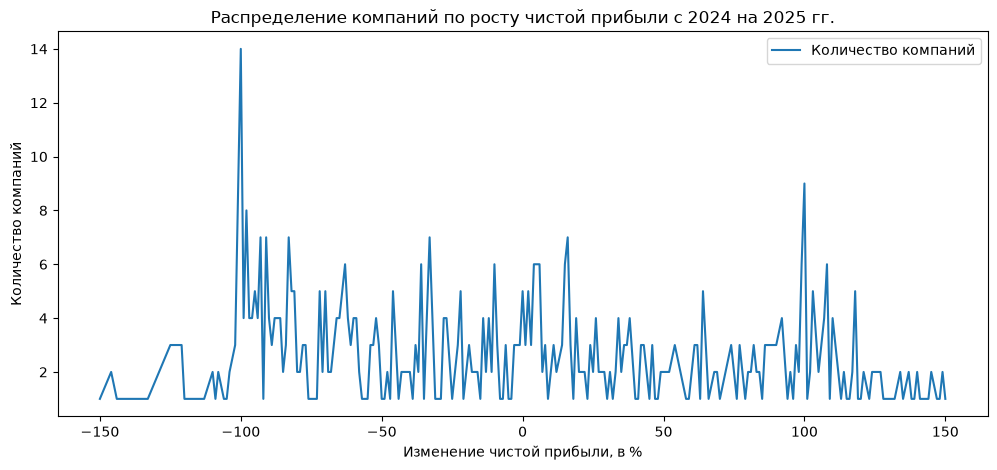

In [23]:
table1.plot.line(
    x = 'Изменение чистой прибыли, в %',
    y = 'Количество компаний',
    figsize = (12,5)
)
plt.xlabel('Изменение чистой прибыли, в %')
plt.ylabel('Количество компаний')
plt.title('Распределение компаний по росту чистой прибыли с 2024 на 2025 гг.')
plt.show()

In [40]:
# Анализ EBITA
print('Средняя EBITA 2025:', round(results_df['EBITA 2025'].mean()))
print('Медианная EBITA 2025:', round(results_df['EBITA 2025'].median()))
print('Средняя EBITA 2024:', round(results_df['EBITA 2024'].mean()))
print('Медианная EBITA 2024:', round(results_df['EBITA 2024'].median()))
print('Положительную EBITA в 2025 году имеют', (results_df['EBITA 2025'] > 0).sum(), 'компаний')
print('Их доля составляет', round(((results_df['EBITA 2025'] > 0).sum() / len(results_df) * 100)), '%')
print('EBITA выросла в 2024-2025 гг. у', (results_df['EBITA 2025'] > results_df['EBITA 2024']).sum(), 'компаний, это составляет', round((results_df['EBITA 2025'] > results_df['EBITA 2024']).sum() / len(results_df) * 100), '% от всех компаний')


Средняя EBITA 2025: 14640
Медианная EBITA 2025: 206
Средняя EBITA 2024: 10756
Медианная EBITA 2024: 202
Положительную EBITA в 2025 году имеют 520 компаний
Их доля составляет 55 %
EBITA выросла в 2024-2025 гг. у 346 компаний, это составляет 37 % от всех компаний


In [5]:
results_top = results_df.copy()
results_top = results_top.sort_values('Выручка 2025', ascending=False)
top500 = results_top.head(500)
print(top500.shape)

(500, 9)


In [ ]:
regions = reestr[['ИНН', 'Регион', 'Район', 'Город', 'Населенный пункт']]
top500 = top500.merge(
    regions[['ИНН', 'Регион', 'Район', 'Город', 'Населенный пункт']],
    on = 'ИНН',
)

In [7]:
top500['Местоположение'] = top500['Город'].fillna(top500['Населенный пункт']).fillna(top500['Район']).fillna(top500['Регион'])
print(top500.head())

          ИНН         Название  Выручка 2025  EBITA 2025  EBITA 2024  \
0  9703109706      ООО "МСУ-1"     8055160.0     38543.0    220150.0   
1  9717029923        ООО "ОСК"     7960613.0     -1855.0     31276.0   
2  5009116873  ООО "МС ПОДРЯД"     6829160.0     -4218.0      7378.0   
3  6167073060        ООО "ЮСК"     4950324.0     29855.0    148223.0   
4  7811598426    ООО "ЛЮНЕТТА"     4701667.0    849884.0   -851335.0   

   Рост EBITA, в %  Чистая прибыль 2025  Чистая прибыль 2024  \
0              -82              50922.0             183192.0   
1             -106               1554.0              27368.0   
2             -157               2120.0               5155.0   
3              -80              18072.0              96840.0   
4              200             788945.0            -842352.0   

   Изменение чистой прибыли, в %                   Регион Район  \
0                          -72.0            77 - г.Москва   NaN   
1                          -94.0            77 -

In [8]:
geolocator = Nominatim(user_agent='my_project')

geocode = RateLimiter(
    geolocator.geocode,
    min_delay_seconds=1
)

latitudes = []
longitudes = []

for place in top500['Местоположение']:
    location = geocode(str(place) + ', Россия')

    if location:
        latitudes.append(location.latitude)
        longitudes.append(location.longitude)
    else:
        latitudes.append(None)
        longitudes.append(None)

top500['Широта'] = latitudes
top500['Долгота'] = longitudes

In [10]:
top500.to_csv('top500.csv', index=False)

In [12]:
map_df = top500.dropna(
    subset=['Широта', 'Долгота']
).copy()

geometry = gpd.points_from_xy(
    map_df['Долгота'],
    map_df['Широта']
)

gdf = gpd.GeoDataFrame(
    map_df,
    geometry=geometry,
    crs='EPSG:4326'
)

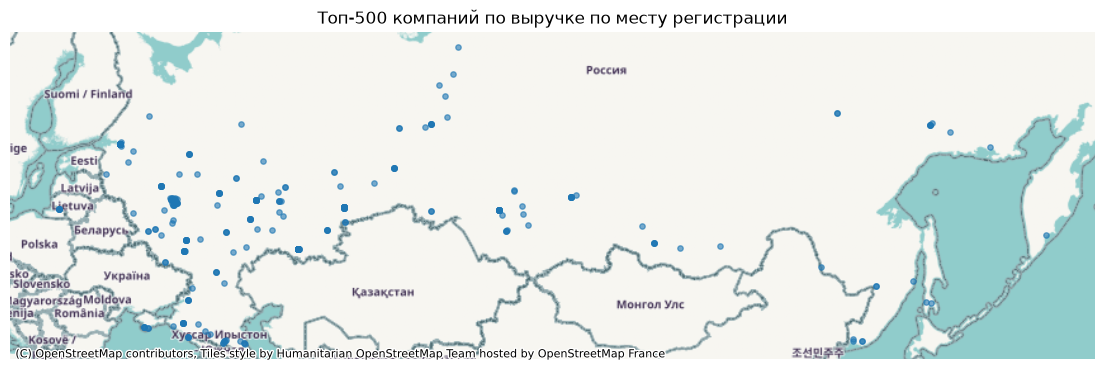

In [18]:
gdf_map = gdf.to_crs(epsg=3857)

ax = gdf_map.plot(
    figsize=(14, 8),
    markersize=15,
    alpha=0.6
)

ctx.add_basemap(ax)

plt.title('Топ-500 компаний по выручке по месту регистрации')
ax.set_axis_off()
plt.show()